# Regression from images — predict and deploy

A trained model is a file. This notebook turns it into answers for new images, a command-line tool, and a demo app.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/regression/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("regression", cfg)
print("task:", "regression", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: regression | data: data/demo/regression | outputs: outputs/regression_quick


## A trained model
This notebook needs `best.pt`; it trains one (quick preset) if you haven't yet.

In [3]:
from cvkit.checkpoint import checkpoint_path
from tasks.regression.train import train

if not checkpoint_path(cfg, "best.pt").exists():     # this notebook needs a trained model; train one if missing
    train(cfg)
print("model:", checkpoint_path(cfg, "best.pt"))

model: outputs/regression_quick/checkpoints/best.pt


## The `Predictor`
One object loads `best.pt` once and answers for a file path or a PIL image. It rebuilds the model from the *checkpoint's own* config, so it keeps working even if you edit the YAML later.

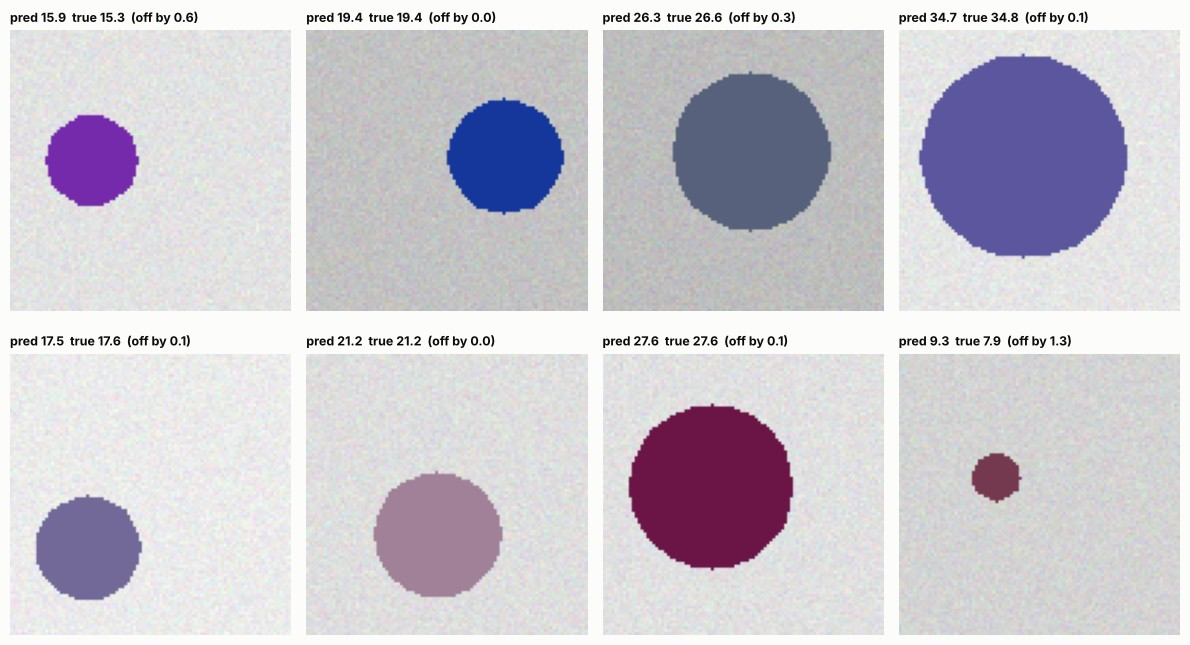

In [4]:
from tasks.regression.predict import Predictor
from tasks.regression.data import build_datasets
from cvkit.viz import image_grid

predictor = Predictor.from_config(cfg)
test = build_datasets(cfg)["test"]
images, titles = [], []
for path, true in test.samples[:8]:
    pred = predictor.predict(path)
    images.append(Image.open(path)); titles.append(f"pred {pred:.1f}  true {true:.1f}  (off by {abs(pred - true):.1f})")
_ = image_grid(images, titles, cols=4)

## A sanity check: does the model respect what shouldn't matter?
Flipping a circle doesn't change its radius, so predictions on the original and the flipped image should agree. Cheap *invariance tests* like this catch models that learned the wrong cue.

In [5]:
from PIL import ImageOps

for path, true in test.samples[:5]:
    img = Image.open(path)
    print(f"true {true:6.2f} | original {predictor.predict(img):6.2f} | mirrored {predictor.predict(ImageOps.mirror(img)):6.2f}")

true  15.29 | original  15.86 | mirrored  16.01
true  19.38 | original  19.36 | mirrored  19.43
true  26.60 | original  26.34 | mirrored  26.28
true  34.80 | original  34.73 | mirrored  34.34
true  17.58 | original  17.46 | mirrored  18.32


## From the command line
```bash
python -m cvkit regression predict --quick --input path/to/image.jpg
python -m cvkit regression predict --quick --input path/to/folder
```
Without `--input` it predicts a few test images. Annotated copies (where the task has them) are saved under `outputs/<run>/predictions/`.

## The demo app
```bash
python -m cvkit regression app --quick            # http://127.0.0.1:7860
python -m cvkit regression app --quick --share    # a temporary public link
```
Or from a notebook cell: `from tasks.regression.app import build_app; build_app(cfg).launch()`.

**Permanent free hosting:** create a *Gradio* Space on [Hugging Face](https://huggingface.co/spaces), upload this repo plus `outputs/<run>/checkpoints/best.pt`, and point the Space at the task's `app.py`.

In [6]:
from tasks.regression.app import build_app

app = build_app(cfg)          # building it proves the app can load the model
print(type(app).__name__, '- call app.launch() to open it in the browser')

Interface - call app.launch() to open it in the browser


## Before you ship
- [ ] The test metrics are what you'd tell a user to expect (not the val numbers)
- [ ] You looked at the worst predictions and know *why* they happen
- [ ] You tried images that look different from your training data (new lighting, camera, background)
- [ ] You know the units, and what error size is acceptable to the person using the prediction
- [ ] You tested inputs outside the training range: regression models don't extrapolate
